# Data Engineering & Visualization - Milestone 1
## Member 3 - Data Integration: Housing (H5) x Transportation (T4)

**Course:** Data Engineering and Visualization, Winter 2026 - GIU
**Team member:** Member 3 (Aya Sweed) - Data integration
**Output of this notebook:** `data/clean/integrated_dataset.csv`: one row per **ZIP code x year (2022-2025)** combining construction activity (Member 1) and serious crashes (Member 2), ready for analysis (Member 4) and the website (Member 5).

**Contents**
1. Inputs, outputs and goal
2. Choosing the integration level (why ZIP code x year)
3. Loading both cleaned files and checking the join keys
4. Merging the datasets (outer join) and reporting the match
5. Post-integration cleaning
6. Derived columns
7. Validation and export
8. Research questions and visualizations (Member 3)
9. Prompts

## 1. Inputs, outputs and goal

| | File | Produced by | Grain |
|---|---|---|---|
| Input 1 | `data/clean/housing_clean.csv` | Member 1 (DOB NOW Build Job Application Filings, H5, `w9ak-ipjd`) | ZIP code x year |
| Input 2 | `data/clean/transport_clean.csv` | Member 2 (SIRTA serious crashes, T4, `xeqp-qz8h`) | ZIP code x year |
| Output | `data/clean/integrated_dataset.csv` | this notebook | ZIP code x year |

**Goal:** put construction activity and serious crashes for the same place and the same year side by side, so we can ask whether the two move together. Both inputs follow the team's data contract (`docs/data_contract.md`): `zip_code` is a 5-digit string, `year` is an integer from 2022 to 2025, `borough` is uppercase, and each (`zip_code`, `year`) pair appears once.

**Note on unit columns:** `proposed_units_total`, `existing_units_total` and `net_new_units` are being corrected by Member 1 (dwelling units were counted once per filing instead of once per job). This notebook runs unchanged on the corrected file; any result that uses unit columns is marked *provisional* until then.

## 2. Choosing the integration level (why ZIP code x year)

The two datasets describe different events, a construction filing and a serious crash, so there is no shared ID to join row by row. We join them on **place and time**: `zip_code` + `year`.

**Why ZIP code x year**
- Both cleaned files are already aggregated to this level, so the join needs no further reshaping.
- It is fine-grained enough to compare neighbourhoods: about 185 ZIP codes x 4 years, so roughly 740 rows.
- A year is the natural unit for both: building filings and crash statistics are both reported and compared annually, and four years let us look at change over time.

**Alternatives considered and rejected**
| Option | Why not |
|---|---|
| **Record level** (each filing joined to each crash) | The project rules forbid it, and it would be meaningless: a filing and a crash are not the same event, so a row-by-row join would multiply rows without linking anything real. |
| **Borough x year** | Only 5 boroughs x 4 years = **20 rows**: too few for any analysis, and it hides big differences between neighbourhoods inside a borough. |
| **Spatial join** (link each crash to construction sites within a radius) | More precise about location, but it needs a distance choice that would drive the results, makes the dataset much larger, and still answers a different (street-level) question than our neighbourhood-level one. A possible extension, not needed here. |
| **Month instead of year** | Many ZIP-months would have zero serious crashes, so the crash numbers become mostly noise. |

**Known limitation of the key (carried over from Member 1)**
H5 has no building ZIP code: its `zip` column is the owner's mailing address. Member 1 assigned each building the ZIP of the **nearest SIRTA crash** within about 1 km (`members/member1_housing/assign_zip_from_sirta.py`). This means:
- roughly 9% of buildings near a ZIP border may get the neighbouring ZIP;
- about 1.4% of filings (no coordinates, or no crash within 1 km) have no ZIP and are not in the housing file;
- a housing ZIP can only exist where crashes happened at some point, so the ZIP coverage of the two files is **not independent**. We keep this in mind when reading the match counts in Section 4.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.max_columns", 60)

# ----------------------------- configuration -----------------------------
# Works whether the notebook runs from the project root or from notebooks/
ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
CLEAN_DIR = os.path.join(ROOT, "data", "clean")
HOUSING_CSV = os.path.join(CLEAN_DIR, "housing_clean.csv")
TRANSPORT_CSV = os.path.join(CLEAN_DIR, "transport_clean.csv")
OUTPUT_CSV = os.path.join(CLEAN_DIR, "integrated_dataset.csv")

KEYS = ["zip_code", "year"]
YEARS = [2022, 2023, 2024, 2025]
BOROUGHS = ["BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"]

for path in (HOUSING_CSV, TRANSPORT_CSV):
    print(f"{path:45s} exists: {os.path.exists(path)}")

..\data\clean\housing_clean.csv               exists: True
..\data\clean\transport_clean.csv             exists: True


## 3. Loading both cleaned files and checking the join keys

A merge is only correct if the keys mean exactly the same thing in both files. Before joining, we check the data contract on **both** sides:

1. `zip_code` is read as **text**, not a number. Read as a number, a ZIP like `"07001"` would lose its leading zero and could silently fail to match. Every value must be exactly 5 digits.
2. `year` is an integer in 2022-2025 in both files. A year stored as `2022.0` in one file and `2022` in the other would not match.
3. The pair (`zip_code`, `year`) is **unique** in each file. If it were not, the merge would multiply rows (one housing row x two crash rows = two output rows) and inflate every total.
4. `borough` uses the same five uppercase labels in both files, because we compare the two `borough` columns after the merge.

Each check is an `assert`, so the notebook stops immediately if a future version of an input file breaks the contract.

In [2]:
housing = pd.read_csv(HOUSING_CSV, dtype={"zip_code": str})
transport = pd.read_csv(TRANSPORT_CSV, dtype={"zip_code": str})

for name, df in [("housing", housing), ("transport", transport)]:
    print(f"{name:10s}: {df.shape[0]:,} rows x {df.shape[1]} columns, "
          f"{df['zip_code'].nunique()} ZIP codes, years {sorted(df['year'].unique().tolist())}")

print("\nHousing columns  :", list(housing.columns))
print("Transport columns:", list(transport.columns))

housing   : 736 rows x 19 columns, 184 ZIP codes, years [2022, 2023, 2024, 2025]
transport : 703 rows x 13 columns, 185 ZIP codes, years [2022, 2023, 2024, 2025]

Housing columns  : ['zip_code', 'year', 'borough', 'filing_count', 'new_construction_filings', 'permit_issued_count', 'proposed_units_total', 'existing_units_total', 'net_new_units', 'initial_cost_total', 'initial_cost_median', 'total_floor_area', 'avg_proposed_stories', 'avg_proposed_height', 'avg_latitude', 'avg_longitude', 'outlier_filing_count', 'outlier_filing_share', 'is_outlier_zip_year']
Transport columns: ['zip_code', 'year', 'borough', 'crash_count', 'severe_injuries_total', 'non_severe_injuries_total', 'fatalities_total', 'fatal_crash_count', 'severe_per_crash', 'night_crash_share', 'avg_latitude', 'avg_longitude', 'is_outlier_zip_year']


In [3]:
def check_keys(df, name):
    assert pd.api.types.is_string_dtype(df["zip_code"]), f"{name}: zip_code must be text"
    assert df["zip_code"].str.fullmatch(r"\d{5}").all(), f"{name}: every zip_code must be 5 digits"
    assert df["zip_code"].notna().all(), f"{name}: zip_code has missing values"
    assert pd.api.types.is_integer_dtype(df["year"]), f"{name}: year must be an integer"
    assert df["year"].isin(YEARS).all(), f"{name}: year outside 2022-2025"
    n_dup = int(df.duplicated(KEYS).sum())
    assert n_dup == 0, f"{name}: {n_dup} duplicated (zip_code, year) pairs"
    assert df["borough"].isin(BOROUGHS).all(), f"{name}: unexpected borough label"
    print(f"{name:10s}: all key checks PASSED "
          f"(5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)")

check_keys(housing, "housing")
check_keys(transport, "transport")

# Rows per year: shows whether either file is missing a year for some ZIP codes
rows_per_year = pd.DataFrame({
    "housing": housing["year"].value_counts().sort_index(),
    "transport": transport["year"].value_counts().sort_index(),
})
rows_per_year.index.name = "year"
rows_per_year

housing   : all key checks PASSED (5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)
transport : all key checks PASSED (5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)


,housing,transport
year,,
2022,184,173
2023,184,174
2024,184,179
2025,184,177


In [4]:
# Columns present in both files (other than the keys): these will collide in the merge
shared = sorted((set(housing.columns) & set(transport.columns)) - set(KEYS))
print("Columns in both files besides the keys:", shared)

Columns in both files besides the keys: ['avg_latitude', 'avg_longitude', 'borough', 'is_outlier_zip_year']


**Result.** Both files pass every key check, so they can be merged directly on `zip_code` + `year` without any conversion.

- The housing file has a row for every one of its ZIP codes in every year, so 184 x 4 = 736 rows.
- The transport file has slightly fewer rows per year than its 185 ZIP codes. A ZIP-year with **no serious crash recorded** simply has no row in Member 2's aggregation. This matters in Section 5, where we decide what a missing crash row means.
- Four columns besides the keys appear in **both** files: `borough`, `avg_latitude`, `avg_longitude`, and `is_outlier_zip_year`. They describe different things in each file (e.g. the centroid of construction filings vs. the centroid of crashes), so they must not be silently merged. They are resolved in Section 5.

## 4. Merging the datasets (outer join) and reporting the match

**Join type: outer.** We keep every ZIP-year that appears in *either* file.
- An **inner** join would keep only ZIP-years present in both files and silently drop the rest. Dropping a ZIP-year with construction but no serious crash would bias the data towards crash-prone places, and that is exactly the relationship we want to study.
- An outer join keeps those rows and lets us decide openly, in Section 5, how to fill the gaps.

`indicator=True` adds a `_merge` column telling us where each row came from (`both`, `left_only` = housing only, `right_only` = transport only). Columns that exist in both files get the suffixes `_housing` / `_transport` so nothing is overwritten.

`validate="one_to_one"` makes pandas raise an error if a key were duplicated in either file, a second guard on top of the checks in Section 3.

In [5]:
merged = pd.merge(
    housing, transport,
    on=KEYS, how="outer",
    suffixes=("_housing", "_transport"),
    indicator=True, validate="one_to_one",
)
merged["match_status"] = merged["_merge"].map({
    "both": "In both files",
    "left_only": "Housing only",
    "right_only": "Transport only",
})
merged = merged.drop(columns="_merge")

print(f"housing rows   : {len(housing):,}")
print(f"transport rows : {len(transport):,}")
print(f"merged rows    : {len(merged):,}  ({merged['zip_code'].nunique()} ZIP codes)\n")
match_counts = merged["match_status"].value_counts().reindex(["In both files", "Housing only", "Transport only"])
print(match_counts.to_string())

# Sanity check: outer join row count = both + housing only + transport only
assert len(merged) == len(housing) + len(transport) - match_counts["In both files"]

housing rows   : 736
transport rows : 703
merged rows    : 738  (185 ZIP codes)

match_status
In both files     701
Housing only       35
Transport only      2


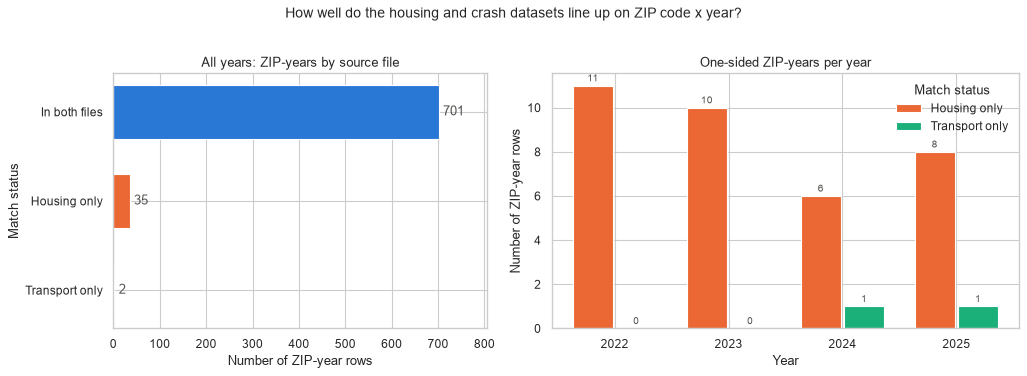

match_status,In both files,Housing only,Transport only
year,,,
2022,173,11,0
2023,174,10,0
2024,178,6,1
2025,176,8,1


In [6]:
# Chart: how well do the two files line up?
STATUS_ORDER = ["In both files", "Housing only", "Transport only"]
STATUS_COLORS = {"In both files": "#2a78d6", "Housing only": "#eb6834", "Transport only": "#1baf7a"}

by_year = (merged.groupby(["year", "match_status"]).size()
           .unstack(fill_value=0).reindex(columns=STATUS_ORDER, fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})

# Left: overall counts
ax = axes[0]
bars = ax.barh(STATUS_ORDER[::-1], match_counts[STATUS_ORDER[::-1]],
               color=[STATUS_COLORS[s] for s in STATUS_ORDER[::-1]], height=0.6)
ax.bar_label(bars, labels=[f"{v:,}" for v in match_counts[STATUS_ORDER[::-1]]], padding=4, color="#52514e")
ax.set_title("All years: ZIP-years by source file")
ax.set_xlabel("Number of ZIP-year rows")
ax.set_ylabel("Match status")
ax.set_xlim(0, match_counts.max() * 1.15)

# Right: the one-sided rows per year (the 'both' bars would dwarf them)
ax = axes[1]
x = np.arange(len(YEARS))
w = 0.38
for i, status in enumerate(["Housing only", "Transport only"]):
    b = ax.bar(x + (i - 0.5) * w, by_year[status].reindex(YEARS, fill_value=0), width=w - 0.03,
               color=STATUS_COLORS[status], label=status)
    ax.bar_label(b, padding=2, color="#52514e", fontsize=9)
ax.set_xticks(x, YEARS)
ax.set_title("One-sided ZIP-years per year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of ZIP-year rows")
ax.legend(title="Match status", frameon=False)

fig.suptitle("How well do the housing and crash datasets line up on ZIP code x year?", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

by_year

In [7]:
# Which ZIP codes are one-sided, and are they one-sided in every year or only some?
housing_zips, transport_zips = set(housing["zip_code"]), set(transport["zip_code"])
print("ZIP codes only in housing  :", sorted(housing_zips - transport_zips) or "none")
print("ZIP codes only in transport:", sorted(transport_zips - housing_zips) or "none")

one_sided = merged[merged["match_status"] != "In both files"]
summary = (one_sided.groupby(["match_status", "zip_code"])
           .agg(borough=("borough_housing", "first"), years=("year", lambda s: sorted(s.tolist())),
                filing_count=("filing_count", "sum"))
           .reset_index())
summary["borough"] = summary["borough"].fillna(
    summary["zip_code"].map(transport.drop_duplicates("zip_code").set_index("zip_code")["borough"]))
summary

ZIP codes only in housing  : none
ZIP codes only in transport: ['10282']


,match_status,zip_code,borough,years,filing_count
0,Housing only,10004,MANHATTAN,"[2022, 2023]",1208.0
1,Housing only,10005,MANHATTAN,[2025],441.0
2,Housing only,10006,MANHATTAN,"[2022, 2025]",92.0
3,Housing only,10020,MANHATTAN,"[2022, 2023, 2025]",483.0
4,Housing only,10111,MANHATTAN,"[2023, 2024]",840.0
5,Housing only,10168,MANHATTAN,"[2022, 2024, 2025]",51.0
6,Housing only,10170,MANHATTAN,"[2022, 2023, 2025]",489.0
7,Housing only,10172,MANHATTAN,"[2023, 2025]",757.0
8,Housing only,10278,MANHATTAN,"[2022, 2023]",175.0
9,Housing only,10280,MANHATTAN,[2025],89.0


**Result.** The outer join produced **738 ZIP-year rows** for 185 ZIP codes: **701 (95%) are in both files**, 35 are housing only and 2 are transport only. The match is very high, but partly by construction: housing ZIP codes were assigned from crash locations (Section 2), so a ZIP code can only appear in the housing file if it had serious crashes in at least one year.

**Housing only (35 ZIP-years, 19 ZIP codes):** construction filings were recorded but Member 2's file has **no serious crash** for that ZIP and year. Every one of these ZIP codes does have crashes in other years. They are mostly very small Manhattan ZIP codes (Financial District, Midtown), several of which cover a single building (e.g. 10111, 10168, 10170, 10172, 10278), plus a few low-traffic edge areas (City Island 10464, the Queens/Nassau border 11001/11004/11040). A year without a serious crash is plausible there, so these rows are real observations of *zero* serious crashes, not missing data.

**Transport only (2 ZIP-years, ZIP 10282, Battery Park City):** serious crashes were recorded in 2024 and 2025, but no filing was assigned this ZIP in any year. With nearest-crash assignment, buildings in this small ZIP were matched to crash points in neighbouring ZIP codes. So its filings are counted elsewhere, not absent. We keep the rows and flag them, rather than reading them as "no construction".

What each kind of gap means, and how it is filled, is decided in Section 5.

## 5. Post-integration cleaning

Merging creates problems that did not exist in either input file. We fix four kinds:

1. **Duplicated columns**: `borough`, `avg_latitude`, `avg_longitude` and `is_outlier_zip_year` now exist twice (`_housing` / `_transport`).
2. **New missing values** created by the outer join: crash columns are empty on the 35 housing-only rows, and housing columns are empty on the 2 transport-only rows.
3. **Source flags**: after filling, we must still be able to tell a real value from a filled one.
4. **Data types**: integer count columns became decimals during the merge, because pandas stores missing numbers as `NaN`, which is a float.

We first record the missing values right after the merge, so we can show a before/after table at the end of this section.

In [8]:
integrated = merged.copy()
missing_before = integrated.isna().sum()
print("Columns with missing values right after the merge:")
print(missing_before[missing_before > 0].to_string())

Columns with missing values right after the merge:
borough_housing                   2
filing_count                      2
new_construction_filings          2
permit_issued_count               2
proposed_units_total              2
existing_units_total              2
net_new_units                     2
initial_cost_total                2
initial_cost_median               2
total_floor_area                  2
avg_proposed_stories              4
avg_proposed_height               4
avg_latitude_housing              2
avg_longitude_housing             2
outlier_filing_count              2
outlier_filing_share              2
is_outlier_zip_year_housing       2
borough_transport                35
crash_count                      35
severe_injuries_total            35
non_severe_injuries_total        35
fatalities_total                 35
fatal_crash_count                35
severe_per_crash                 35
night_crash_share                35
avg_latitude_transport           38
avg_longitude

### 5.1 Duplicated columns

**`borough`.** We compare the two versions wherever both exist. If they disagreed, the same ZIP code would sit in two boroughs, which would point to a ZIP-assignment error. Then we keep one column, taking the housing value and filling from transport where housing is missing (ZIP 10282).

In [9]:
both_present = integrated["borough_housing"].notna() & integrated["borough_transport"].notna()
conflicts = integrated[both_present & (integrated["borough_housing"] != integrated["borough_transport"])]
print(f"Rows where both files give a borough: {both_present.sum()}")
print(f"Rows where they disagree           : {len(conflicts)}")

integrated["borough"] = integrated["borough_housing"].fillna(integrated["borough_transport"])
assert integrated["borough"].isin(BOROUGHS).all()

# A ZIP code must belong to exactly one borough across all years
assert (integrated.groupby("zip_code")["borough"].nunique() == 1).all(), "a ZIP code maps to two boroughs"
print("Every ZIP code maps to exactly one borough.")

Rows where both files give a borough: 701
Rows where they disagree           : 0
Every ZIP code maps to exactly one borough.


**`avg_latitude` / `avg_longitude`.** These mean different things: the housing pair is the centre of that year's *construction filings*, while the transport pair is the centre of that year's *crashes*. They also move from year to year with wherever activity happened. Keeping four coordinate columns would confuse the people using the file. They are only needed to place a ZIP code on a map (Members 4 and 5), so we replace them with **one fixed point per ZIP code**: `zip_latitude` / `zip_longitude`, the mean of all available housing and crash centroids for that ZIP across all years. This also gives a location to rows where one side is missing. We first measure how far apart the two centres are, to show that averaging them is reasonable.

In [10]:
lat_cols = ["avg_latitude_housing", "avg_latitude_transport"]
lon_cols = ["avg_longitude_housing", "avg_longitude_transport"]

# Distance between filing centre and crash centre in the same ZIP-year (1 degree of latitude ~ 111 km)
dist_km = np.hypot(
    integrated["avg_latitude_housing"] - integrated["avg_latitude_transport"],
    (integrated["avg_longitude_housing"] - integrated["avg_longitude_transport"]) * np.cos(np.radians(40.7)),
) * 111
print(f"Filing centre vs crash centre, same ZIP-year: median {dist_km.median():.2f} km, "
      f"90th percentile {dist_km.quantile(0.9):.2f} km, max {dist_km.max():.2f} km")

long_coords = pd.concat([
    integrated[["zip_code", "avg_latitude_housing", "avg_longitude_housing"]].set_axis(["zip_code", "lat", "lon"], axis=1),
    integrated[["zip_code", "avg_latitude_transport", "avg_longitude_transport"]].set_axis(["zip_code", "lat", "lon"], axis=1),
])
zip_centroids = (long_coords.groupby("zip_code")[["lat", "lon"]].mean().round(6)
                 .rename(columns={"lat": "zip_latitude", "lon": "zip_longitude"}))
integrated = integrated.merge(zip_centroids, on="zip_code", how="left")
assert integrated[["zip_latitude", "zip_longitude"]].notna().all().all()
print(f"One fixed centroid for each of {len(zip_centroids)} ZIP codes; no missing coordinates.")

Filing centre vs crash centre, same ZIP-year: median 0.24 km, 90th percentile 0.59 km, max 3.48 km
One fixed centroid for each of 185 ZIP codes; no missing coordinates.


**`is_outlier_zip_year`.** The two flags answer different questions: *unusually many filings* (housing) vs *unusually many crashes* (transport). Both are useful, so we keep both under clear names: `is_outlier_housing` and `is_outlier_transport`. Where a side has no data, there is nothing to be an outlier, so the flag is `False`; the source flags added in 5.3 show that case explicitly.

In [11]:
integrated["is_outlier_housing"] = integrated["is_outlier_zip_year_housing"].fillna(False).astype(bool)
integrated["is_outlier_transport"] = integrated["is_outlier_zip_year_transport"].fillna(False).astype(bool)

integrated = integrated.drop(columns=[
    "borough_housing", "borough_transport",
    "avg_latitude_housing", "avg_latitude_transport", "avg_longitude_housing", "avg_longitude_transport",
    "is_outlier_zip_year_housing", "is_outlier_zip_year_transport",
])
print(integrated["is_outlier_housing"].sum(), "housing outlier rows;",
      integrated["is_outlier_transport"].sum(), "transport outlier rows")

100 housing outlier rows; 4 transport outlier rows


### 5.2 Missing values created by the join

**Crash columns on the 35 housing-only rows: filled with 0.** SIRTA aims to record *every* serious-injury crash in NYC, and Section 4 showed that all of these ZIP codes have crashes in other years. So a missing row means *no serious crash was recorded* in that ZIP and year, which is a true zero, not unknown. We fill the **count** columns (`crash_count`, `severe_injuries_total`, `non_severe_injuries_total`, `fatalities_total`, `fatal_crash_count`) with 0.

**Crash rates stay missing.** `severe_per_crash` and `night_crash_share` are shares *of crashes*. With zero crashes they are 0 / 0, which is undefined, so filling them with 0 would wrongly say "no crash was severe / at night". They stay `NaN`.

**Housing columns on the 2 transport-only rows (ZIP 10282): left missing, and flagged.** Here a missing row does **not** mean zero construction: Section 4 showed that this ZIP's filings were assigned to neighbouring ZIP codes by the nearest-crash method. Filling `filing_count = 0` would invent a fact, so these values stay `NaN` and the row is marked with `has_housing_data = False` (5.3). Analyses that need housing values simply exclude these 2 rows.

**Pre-existing gaps (not caused by the join).** `avg_proposed_stories` and `avg_proposed_height` are missing on 2 rows where *every* filing in that ZIP-year left height and stories blank (e.g. interior work). The average is undefined, so they stay `NaN`.

In [12]:
CRASH_COUNTS = ["crash_count", "severe_injuries_total", "non_severe_injuries_total",
                "fatalities_total", "fatal_crash_count"]
CRASH_RATES = ["severe_per_crash", "night_crash_share"]

housing_only = integrated["match_status"] == "Housing only"
transport_only = integrated["match_status"] == "Transport only"

# Only the housing-only rows may be missing crash counts; check before filling
assert integrated.loc[~housing_only, CRASH_COUNTS].notna().all().all()
integrated[CRASH_COUNTS] = integrated[CRASH_COUNTS].fillna(0)

print(f"Filled crash counts with 0 on {housing_only.sum()} housing-only rows.")
print(f"Crash rates left NaN (0 crashes -> rate undefined): {integrated[CRASH_RATES].isna().sum().to_dict()}")
print(f"Housing values left NaN on {transport_only.sum()} transport-only rows: "
      f"{integrated.loc[transport_only, ['zip_code', 'year']].values.tolist()}")

Filled crash counts with 0 on 35 housing-only rows.
Crash rates left NaN (0 crashes -> rate undefined): {'severe_per_crash': 35, 'night_crash_share': 35}
Housing values left NaN on 2 transport-only rows: [['10282', 2024], ['10282', 2025]]


### 5.3 Source flags

Two boolean columns record where each row's data came from, so filled values can always be told apart from observed ones:
- `has_housing_data`: `True` if the housing file had a row for this ZIP-year (`False` only for ZIP 10282, 2024-2025).
- `has_crash_data`: `True` if the crash file had a row (`False` for the 35 rows whose crash counts were filled with 0).

They replace the temporary `match_status` column.

In [13]:
integrated["has_housing_data"] = integrated["match_status"] != "Transport only"
integrated["has_crash_data"] = integrated["match_status"] != "Housing only"
integrated = integrated.drop(columns="match_status")

pd.crosstab(integrated["has_housing_data"], integrated["has_crash_data"], margins=True)

has_crash_data,False,True,All
has_housing_data,,,
False,0,2,2
True,35,701,736
All,35,703,738


### 5.4 Data types and column order

- `zip_code` stays text, and `year` an integer.
- Count columns go back to whole numbers. Housing counts use pandas' nullable integer type `Int64`, which can hold a missing value (ZIP 10282) without becoming a decimal. Crash counts have no missing values left, so they become plain `int`.
- Money, area and averages stay decimal.
- Columns are ordered as keys, location, source flags, housing, crashes, outlier flags, so the file reads left to right.

In [14]:
HOUSING_COUNTS = ["filing_count", "new_construction_filings", "permit_issued_count", "outlier_filing_count"]
for col in HOUSING_COUNTS:
    integrated[col] = integrated[col].round().astype("Int64")
for col in CRASH_COUNTS:
    integrated[col] = integrated[col].round().astype(int)
integrated["zip_code"] = integrated["zip_code"].astype(str)
integrated["year"] = integrated["year"].astype(int)

REPLACED = ["borough", "avg_latitude", "avg_longitude", "is_outlier_zip_year"]
HOUSING_COLS = [c for c in housing.columns if c not in KEYS + REPLACED]
TRANSPORT_COLS = [c for c in transport.columns if c not in KEYS + REPLACED]
ORDER = (KEYS + ["borough", "zip_latitude", "zip_longitude", "has_housing_data", "has_crash_data"]
         + HOUSING_COLS + TRANSPORT_COLS + ["is_outlier_housing", "is_outlier_transport"])
assert set(ORDER) == set(integrated.columns), set(integrated.columns) ^ set(ORDER)
integrated = integrated[ORDER].sort_values(KEYS).reset_index(drop=True)

integrated.dtypes.to_frame("dtype").T

,zip_code,year,borough,zip_latitude,zip_longitude,has_housing_data,has_crash_data,filing_count,new_construction_filings,permit_issued_count,proposed_units_total,existing_units_total,net_new_units,initial_cost_total,initial_cost_median,total_floor_area,avg_proposed_stories,avg_proposed_height,outlier_filing_count,outlier_filing_share,crash_count,severe_injuries_total,non_severe_injuries_total,fatalities_total,fatal_crash_count,severe_per_crash,night_crash_share,is_outlier_housing,is_outlier_transport
dtype,str,int64,str,float64,float64,bool,bool,Int64,Int64,Int64,float64,float64,float64,float64,float64,float64,float64,float64,Int64,float64,int64,int64,int64,int64,int64,float64,float64,bool,bool


### 5.5 Before / after: missing values

In [15]:
missing_after = integrated.isna().sum()

def why_missing(col):
    if missing_after[col] == 0:
        return ""
    if col in CRASH_RATES:
        return "0 crashes recorded -> rate undefined"
    if col in ("avg_proposed_stories", "avg_proposed_height"):
        return "no filing reported it + ZIP 10282"
    return "ZIP 10282: no filings assigned (has_housing_data = False)"

mv = pd.DataFrame({
    "missing_after_merge": missing_before.reindex(integrated.columns),
    "missing_after_cleaning": missing_after,
}).fillna(0).astype(int)
mv = mv[(mv > 0).any(axis=1)]
mv["why_still_missing"] = [why_missing(c) for c in mv.index]
mv

,missing_after_merge,missing_after_cleaning,why_still_missing
filing_count,2,2,ZIP 10282: no filings assigned (has_housing_da...
new_construction_filings,2,2,ZIP 10282: no filings assigned (has_housing_da...
permit_issued_count,2,2,ZIP 10282: no filings assigned (has_housing_da...
proposed_units_total,2,2,ZIP 10282: no filings assigned (has_housing_da...
existing_units_total,2,2,ZIP 10282: no filings assigned (has_housing_da...
net_new_units,2,2,ZIP 10282: no filings assigned (has_housing_da...
initial_cost_total,2,2,ZIP 10282: no filings assigned (has_housing_da...
initial_cost_median,2,2,ZIP 10282: no filings assigned (has_housing_da...
total_floor_area,2,2,ZIP 10282: no filings assigned (has_housing_da...
avg_proposed_stories,4,4,no filing reported it + ZIP 10282


**Result.** After cleaning, the integrated table has one `borough` (no conflicts between the files), one fixed map position per ZIP code, two clearly named outlier flags, and two source flags. Every remaining missing value has a stated reason:
- **Housing columns** are missing only on the 2 ZIP 10282 rows (`has_housing_data = False`).
- **Crash rates** are missing on the 35 rows with zero recorded crashes.
- **Average stories/height** are missing where no filing reported them.

Nothing was filled with a number we cannot defend.

## 6. Derived columns

Raw counts mostly measure **how big and busy a ZIP code is**: a large, dense ZIP has both more filings and more crashes. To compare places fairly and to look at change over time, we add five derived columns:

| Column | Formula | Why it is useful | Missing when |
|---|---|---|---|
| `crashes_per_100_filings` | `crash_count / filing_count x 100` | Puts crashes and construction on one scale per ZIP-year | no housing data (ZIP 10282) |
| `filing_change_yoy` | `filing_count` minus the same ZIP's previous year | Change in construction activity, so each ZIP is compared with itself | 2022 (no 2021 data), or previous year missing |
| `crash_change_yoy` | `crash_count` minus the same ZIP's previous year | Change in serious crashes | same as above |
| `crashes_next_year` | the same ZIP's `crash_count` in `year + 1` | Lets us ask whether activity in one year goes with crashes the **following** year | 2025 (no 2026 data) |
| `severe_injuries_per_1000_units` | `severe_injuries_total / proposed_units_total x 1000` | Serious injuries relative to housing being built | `proposed_units_total` is 0 or missing |

**Design choices**
- **Absolute, not percentage, change.** A quarter of ZIP-years have 7 or fewer serious crashes (some only 1), so going from 1 to 3 crashes would read as "+200%". Absolute differences are more stable and easier to read.
- **Year-over-year values are matched on `year - 1` / `year + 1`**, not by row position, so a ZIP with a missing year can never be paired with the wrong year.
- **`crashes_next_year` is blank for 2025, not 0.** 2026 is outside the study window, so the value is unknown, not zero. Any lagged analysis uses 2022-2024 only.
- **PROVISIONAL: `severe_injuries_per_1000_units`.** It uses `proposed_units_total`, which Member 1 is correcting (units were counted once per filing instead of once per job). We use proposed units rather than `net_new_units` because net units can be negative, and dividing by a negative makes no sense. Do not draw conclusions from this column until the corrected housing file is in. It is also unstable where very few units are proposed: a ZIP-year with 1 proposed unit and 1 severe injury scores 1,000.

In [16]:
# 1. Rate: serious crashes per 100 construction filings (Int64 -> float so missing stays NaN)
filings = integrated["filing_count"].astype("float")
integrated["crashes_per_100_filings"] = (integrated["crash_count"] / filings * 100).round(2)

# 2-3. Year-over-year change, matched on year - 1 (not on row position)
prev = integrated[KEYS + ["filing_count", "crash_count"]].copy()
prev["year"] = prev["year"] + 1                      # last year's values, labelled with this year
prev = prev.rename(columns={"filing_count": "filing_prev", "crash_count": "crash_prev"})
integrated = integrated.merge(prev, on=KEYS, how="left")
integrated["filing_change_yoy"] = (integrated["filing_count"].astype("float") - integrated["filing_prev"].astype("float"))
integrated["crash_change_yoy"] = integrated["crash_count"] - integrated["crash_prev"]

# 4. Next year's crashes, matched on year + 1
nxt = integrated[KEYS + ["crash_count"]].copy()
nxt["year"] = nxt["year"] - 1                        # next year's values, labelled with this year
nxt = nxt.rename(columns={"crash_count": "crashes_next_year"})
integrated = integrated.merge(nxt, on=KEYS, how="left").drop(columns=["filing_prev", "crash_prev"])

# 5. PROVISIONAL: severe injuries per 1,000 proposed dwelling units (0 units -> undefined)
units = integrated["proposed_units_total"].where(integrated["proposed_units_total"] > 0)
integrated["severe_injuries_per_1000_units"] = (integrated["severe_injuries_total"] / units * 1000).round(3)

# Whole-number columns keep a nullable integer type
for col in ["filing_change_yoy", "crash_change_yoy", "crashes_next_year"]:
    integrated[col] = integrated[col].round().astype("Int64")

DERIVED = ["crashes_per_100_filings", "filing_change_yoy", "crash_change_yoy",
           "crashes_next_year", "severe_injuries_per_1000_units"]
integrated[DERIVED].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
crashes_per_100_filings,736.0,2.272948,1.878162,0.0,0.9975,1.92,3.1375,25.0
filing_change_yoy,552.0,30.016304,102.53754,-485.0,-28.0,13.5,78.25,440.0
crash_change_yoy,553.0,0.410488,5.817237,-20.0,-2.0,0.0,4.0,21.0
crashes_next_year,553.0,14.560579,10.436681,0.0,6.0,13.0,22.0,48.0
severe_injuries_per_1000_units,726.0,5.337481,38.127495,0.0,0.26875,0.961,3.106,1000.0


In [17]:
# Checks: each derived column is missing exactly where the table above says it should be
first_year = integrated.groupby("zip_code")["year"].transform("min")
assert integrated.loc[integrated["year"] == 2025, "crashes_next_year"].isna().all()
assert integrated.loc[integrated["year"] < 2025, "crashes_next_year"].notna().all()
assert integrated.loc[integrated["year"] == first_year, "crash_change_yoy"].isna().all()
assert integrated.loc[integrated["year"] > first_year, "crash_change_yoy"].notna().all()
assert integrated.loc[~integrated["has_housing_data"], "crashes_per_100_filings"].isna().all()

missing_derived = pd.DataFrame({
    "missing": integrated[DERIVED].isna().sum(),
    "reason": ["ZIP 10282 has no housing data",
               "first year of each ZIP (2022; 2024 for ZIP 10282) + ZIP 10282",
               "first year of each ZIP (2022; 2024 for ZIP 10282)",
               "2025: next year (2026) is outside the data",
               "proposed_units_total is 0 or missing"],
})
missing_derived

,missing,reason
crashes_per_100_filings,2,ZIP 10282 has no housing data
filing_change_yoy,186,first year of each ZIP (2022; 2024 for ZIP 102...
crash_change_yoy,185,first year of each ZIP (2022; 2024 for ZIP 10282)
crashes_next_year,185,2025: next year (2026) is outside the data
severe_injuries_per_1000_units,12,proposed_units_total is 0 or missing


In [18]:
# Example: one ZIP code over the four years, to check the derived columns by eye
integrated.loc[integrated["zip_code"] == "11207",
               KEYS + ["filing_count", "crash_count", "severe_injuries_total", "proposed_units_total"] + DERIVED]

,zip_code,year,filing_count,crash_count,severe_injuries_total,proposed_units_total,crashes_per_100_filings,filing_change_yoy,crash_change_yoy,crashes_next_year,severe_injuries_per_1000_units
398,11207,2022,1227,42,40,49943.0,3.42,<NA>,<NA>,38,0.801
399,11207,2023,1227,38,38,43791.0,3.10,0,-4,48,0.868
400,11207,2024,1419,48,46,39754.0,3.38,192,10,28,1.157
401,11207,2025,1409,28,27,40725.0,1.99,-10,-20,<NA>,0.663


**Result.** The five derived columns behave as designed. Each one is blank only where the value is truly unknown or undefined: the first year for changes, 2025 for next-year crashes, ZIP 10282 for housing-based rates, and zero units for the per-unit rate. The ZIP 11207 example (East New York, Brooklyn) can be checked by hand. For instance, each year's `crashes_next_year` equals the next row's `crash_count`, and `crash_change_yoy` equals this year's minus last year's `crash_count`.

`severe_injuries_per_1000_units` is **provisional** until Member 1's corrected unit columns are merged; this notebook will be re-run then without code changes.

## 7. Validation and export

Before saving, we check that the integration **lost nothing, duplicated nothing, and invented nothing**:

1. **Row count**: an outer join must give `housing rows + transport rows - matched rows` = 736 + 703 - 701 = **738**.
2. **Keys**: (`zip_code`, `year`) is still unique, and every ZIP code has all four years (except ZIP 10282, which only has crash rows in 2024-2025).
3. **Totals reconcile**: summed over the whole table, every count column must equal the same sum in its source file. If a total changed, rows were dropped or duplicated somewhere.
4. **Data contract**: 5-digit text ZIPs, integer years 2022-2025, uppercase boroughs, lowercase_with_underscores column names.

Then we export the file and **read it back** to confirm the saved CSV keeps `zip_code` as text with leading zeros.

In [19]:
expected_rows = len(housing) + len(transport) - int((integrated["has_housing_data"] & integrated["has_crash_data"]).sum())
assert len(integrated) == expected_rows == 738, f"{len(integrated)} rows, expected {expected_rows}"
assert not integrated.duplicated(KEYS).any(), "duplicate (zip_code, year)"

years_per_zip = integrated.groupby("zip_code")["year"].nunique()
assert (years_per_zip.drop("10282") == 4).all() and years_per_zip["10282"] == 2

# Totals must match the source files exactly
recon = []
for col in ["filing_count", "new_construction_filings", "permit_issued_count", "initial_cost_total"]:
    recon.append((col, "housing", housing[col].sum(), integrated[col].astype("float").sum()))
for col in CRASH_COUNTS:
    recon.append((col, "transport", transport[col].sum(), integrated[col].sum()))
recon = pd.DataFrame(recon, columns=["column", "source_file", "source_total", "integrated_total"])
recon["match"] = np.isclose(recon["source_total"].astype(float), recon["integrated_total"].astype(float))
assert recon["match"].all(), "a total changed during integration"
for col in ["source_total", "integrated_total"]:
    recon[col] = recon[col].astype(float).map("{:,.0f}".format)

check_keys(integrated, "integrated")
assert all(c == c.lower() and " " not in c for c in integrated.columns)
print(f"{len(integrated)} rows = {integrated['zip_code'].nunique()} ZIP codes x up to 4 years; "
      f"{integrated.shape[1]} columns. All validation checks PASSED.")
recon

integrated: all key checks PASSED (5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)
738 rows = 185 ZIP codes x up to 4 years; 34 columns. All validation checks PASSED.


,column,source_file,source_total,integrated_total,match
0,filing_count,housing,"589,471","589,471",True
1,new_construction_filings,housing,"74,152","74,152",True
2,permit_issued_count,housing,"230,301","230,301",True
3,initial_cost_total,housing,"161,525,860,741","161,525,860,741",True
4,crash_count,transport,"10,561","10,561",True
5,severe_injuries_total,transport,"10,802","10,802",True
6,non_severe_injuries_total,transport,"2,749","2,749",True
7,fatalities_total,transport,644,644,True
8,fatal_crash_count,transport,617,617,True


In [20]:
# Column summary (data dictionary for Members 4 and 5)
DESCRIPTIONS = {
    "zip_code": "5-digit ZIP code (text)", "year": "calendar year 2022-2025",
    "borough": "NYC borough (uppercase)",
    "zip_latitude": "fixed map point of the ZIP: mean of filing and crash centres, all years",
    "zip_longitude": "fixed map point of the ZIP (see zip_latitude)",
    "has_housing_data": "False = no housing row (ZIP 10282); housing columns blank",
    "has_crash_data": "False = no serious crash recorded; crash counts filled with 0",
    "filing_count": "construction job filings (H5) in the ZIP-year",
    "new_construction_filings": "filings for new buildings",
    "permit_issued_count": "filings that reached permit issued / LOC issued",
    "proposed_units_total": "sum of proposed dwelling units (being corrected by Member 1)",
    "existing_units_total": "sum of existing dwelling units (being corrected by Member 1)",
    "net_new_units": "proposed minus existing units (being corrected by Member 1)",
    "initial_cost_total": "sum of declared job cost, USD",
    "initial_cost_median": "median declared job cost, USD",
    "total_floor_area": "sum of construction floor area, sq ft",
    "avg_proposed_stories": "mean proposed stories (filings that report it)",
    "avg_proposed_height": "mean proposed height, ft (filings that report it)",
    "outlier_filing_count": "filings flagged as outliers by Member 1",
    "outlier_filing_share": "share of filings flagged as outliers",
    "crash_count": "serious-injury crashes (SIRTA, T4)",
    "severe_injuries_total": "people seriously injured",
    "non_severe_injuries_total": "people with non-serious injuries in those crashes",
    "fatalities_total": "people killed",
    "fatal_crash_count": "crashes with at least one death",
    "severe_per_crash": "serious injuries per crash (blank if 0 crashes)",
    "night_crash_share": "share of crashes at night (blank if 0 crashes)",
    "is_outlier_housing": "unusually high filing_count (Member 1's IQR flag)",
    "is_outlier_transport": "unusually high crash_count (Member 2's IQR flag)",
    "crashes_per_100_filings": "crash_count / filing_count x 100",
    "filing_change_yoy": "filing_count minus previous year (blank in first year)",
    "crash_change_yoy": "crash_count minus previous year (blank in first year)",
    "crashes_next_year": "crash_count of the same ZIP in year + 1 (blank for 2025)",
    "severe_injuries_per_1000_units": "PROVISIONAL: severe injuries per 1,000 proposed units",
}
assert set(DESCRIPTIONS) == set(integrated.columns), set(DESCRIPTIONS) ^ set(integrated.columns)
column_summary = pd.DataFrame({
    "dtype": integrated.dtypes.astype(str),
    "missing": integrated.isna().sum(),
    "example (ZIP 11207, 2023)": integrated[(integrated["zip_code"] == "11207") & (integrated["year"] == 2023)].iloc[0].astype(str),
    "description": pd.Series(DESCRIPTIONS),
})
column_summary

,dtype,missing,"example (ZIP 11207, 2023)",description
zip_code,str,0,11207,5-digit ZIP code (text)
year,int64,0,2023,calendar year 2022-2025
borough,str,0,BROOKLYN,NYC borough (uppercase)
zip_latitude,float64,0,40.670013,fixed map point of the ZIP: mean of filing and...
zip_longitude,float64,0,-73.894001,fixed map point of the ZIP (see zip_latitude)
has_housing_data,bool,0,True,False = no housing row (ZIP 10282); housing co...
has_crash_data,bool,0,True,False = no serious crash recorded; crash count...
filing_count,Int64,2,1227,construction job filings (H5) in the ZIP-year
new_construction_filings,Int64,2,321,filings for new buildings
permit_issued_count,Int64,2,399,filings that reached permit issued / LOC issued


In [21]:
integrated.to_csv(OUTPUT_CSV, index=False, encoding="utf-8")

# Read the saved file back exactly as Members 4 and 5 will
reloaded = pd.read_csv(OUTPUT_CSV, dtype={"zip_code": str})
check_keys(reloaded, "reloaded CSV")
assert reloaded.shape == integrated.shape
print(f"Saved {OUTPUT_CSV}: {reloaded.shape[0]} rows x {reloaded.shape[1]} columns "
      f"({os.path.getsize(OUTPUT_CSV) / 1024:.0f} KB)")
print("Load it with: pd.read_csv('data/clean/integrated_dataset.csv', dtype={'zip_code': str})")

reloaded CSV: all key checks PASSED (5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)
Saved ..\data\clean\integrated_dataset.csv: 738 rows x 34 columns (146 KB)
Load it with: pd.read_csv('data/clean/integrated_dataset.csv', dtype={'zip_code': str})


**Result.** `data/clean/integrated_dataset.csv` has **738 rows** (185 ZIP codes, 2022-2025). It passes every validation check:
- no duplicate keys;
- every ZIP code has all four years (ZIP 10282 has two);
- every filing and crash total exactly matches its source file, so nothing was lost or double-counted;
- it meets the data contract.

The column summary above is the data dictionary for Members 4 and 5. **Load the file with `dtype={'zip_code': str}`** so ZIP codes stay text.

## 8. Research questions and visualizations (Member 3)

Both questions use the **integrated** dataset: they need construction and crash data side by side, so neither could be answered from one input file alone.

**Why not just correlate filings with crashes?** Across ZIP codes, busy places have more of everything: more people, traffic, buildings, filings *and* crashes. A raw "more filings, more crashes" correlation mostly measures ZIP size, not any link between construction and road safety. Both questions below therefore compare each ZIP code **with itself over time**, which removes the fixed differences in size between ZIP codes.

### 8.1 Research question 1

> **RQ1: Did ZIP codes whose construction activity grew the most between 2022 and 2025 also see a larger change in serious crashes?**

- **Measure:** for each ZIP code, the change in `filing_count` from 2022 to 2025 against the change in `crash_count` over the same years.
- **Rows used:** the 184 ZIP codes with housing data in both years (ZIP 10282 has no housing data and is excluded).
- **Statistics:** Pearson r (linear) and Spearman rho (rank-based, less sensitive to a few extreme ZIP codes), each with its p-value.

In [22]:
from scipy import stats

BOROUGH_COLORS = {"BRONX": "#2a78d6", "BROOKLYN": "#eb6834", "MANHATTAN": "#1baf7a",
                  "QUEENS": "#eda100", "STATEN ISLAND": "#e87ba4"}

wide = (integrated[integrated["has_housing_data"]]
        .pivot(index="zip_code", columns="year", values=["filing_count", "crash_count"]).astype(float))
rq1 = pd.DataFrame({
    "filing_change": wide[("filing_count", 2025)] - wide[("filing_count", 2022)],
    "crash_change": wide[("crash_count", 2025)] - wide[("crash_count", 2022)],
    "crashes_2022": wide[("crash_count", 2022)],
}).dropna()
rq1["borough"] = rq1.index.map(integrated.drop_duplicates("zip_code").set_index("zip_code")["borough"])

r, p_r = stats.pearsonr(rq1["filing_change"], rq1["crash_change"])
rho, p_rho = stats.spearmanr(rq1["filing_change"], rq1["crash_change"])
print(f"ZIP codes used: {len(rq1)}")
print(f"Change in filings 2022->2025: median {rq1['filing_change'].median():+.0f} (range {rq1['filing_change'].min():+.0f} to {rq1['filing_change'].max():+.0f})")
print(f"Change in crashes 2022->2025: median {rq1['crash_change'].median():+.0f} (range {rq1['crash_change'].min():+.0f} to {rq1['crash_change'].max():+.0f})")
print(f"Pearson r = {r:.3f} (p = {p_r:.2f});  Spearman rho = {rho:.3f} (p = {p_rho:.2f})")

# Check: is crash change just regression to the mean (high-crash ZIPs falling back)?
print(f"Correlation of crash change with 2022 crash level: {rq1['crash_change'].corr(rq1['crashes_2022']):.2f}")

by_boro = rq1.groupby("borough").apply(lambda g: pd.Series({
    "zip_codes": len(g), "median_filing_change": g["filing_change"].median(),
    "median_crash_change": g["crash_change"].median(),
    "pearson_r": g["filing_change"].corr(g["crash_change"])})).round(2)
by_boro

ZIP codes used: 184
Change in filings 2022->2025: median +86 (range -279 to +578)
Change in crashes 2022->2025: median +1 (range -20 to +30)
Pearson r = -0.067 (p = 0.37);  Spearman rho = -0.075 (p = 0.31)
Correlation of crash change with 2022 crash level: -0.24


,zip_codes,median_filing_change,median_crash_change,pearson_r
borough,,,,
BRONX,25.0,118.0,-2.0,0.33
BROOKLYN,39.0,112.0,3.0,0.04
MANHATTAN,49.0,25.0,0.0,-0.21
QUEENS,60.0,74.0,2.0,-0.17
STATEN ISLAND,11.0,203.0,1.0,-0.41


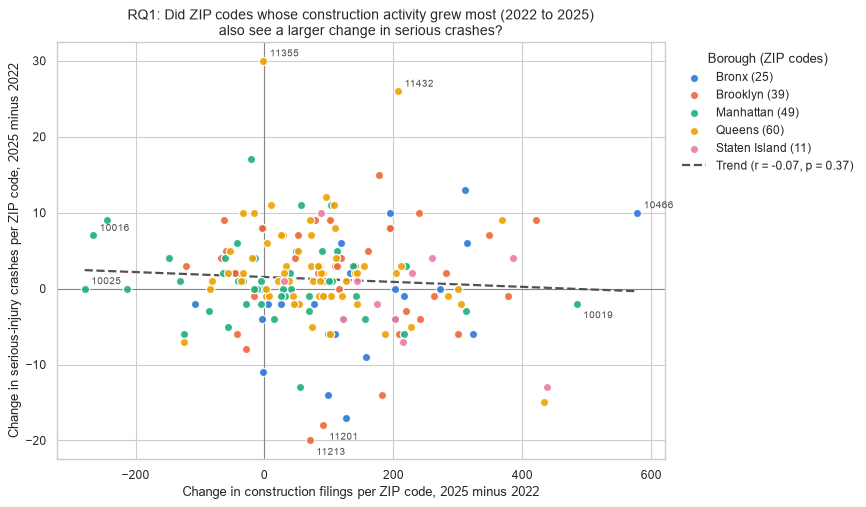

In [23]:
fig, ax = plt.subplots(figsize=(11, 6.5))

for boro in BOROUGHS:
    g = rq1[rq1["borough"] == boro]
    ax.scatter(g["filing_change"], g["crash_change"], s=55, color=BOROUGH_COLORS[boro],
               edgecolor="white", linewidth=1.2, alpha=0.9, label=f"{boro.title()} ({len(g)})", zorder=3)

# Least-squares trend line over all ZIP codes
slope, intercept = np.polyfit(rq1["filing_change"], rq1["crash_change"], 1)
xs = np.linspace(rq1["filing_change"].min(), rq1["filing_change"].max(), 100)
ax.plot(xs, slope * xs + intercept, color="#52514e", linewidth=2, linestyle="--", zorder=2,
        label=f"Trend (r = {r:.2f}, p = {p_r:.2f})")

ax.axhline(0, color="#898781", linewidth=1, zorder=1)
ax.axvline(0, color="#898781", linewidth=1, zorder=1)

# Label only the most extreme ZIP codes on each axis
to_label = set(rq1["filing_change"].nlargest(2).index) | set(rq1["filing_change"].nsmallest(2).index) \
         | set(rq1["crash_change"].nlargest(2).index) | set(rq1["crash_change"].nsmallest(2).index)
for z in to_label:
    ax.annotate(z, (rq1.loc[z, "filing_change"], rq1.loc[z, "crash_change"]),
                xytext=(6, -13 if rq1.loc[z, "crash_change"] < 0 else 4), textcoords="offset points",
                fontsize=9, color="#52514e")

ax.set_title("RQ1: Did ZIP codes whose construction activity grew most (2022 to 2025)\n"
             "also see a larger change in serious crashes?", fontsize=13)
ax.set_xlabel("Change in construction filings per ZIP code, 2025 minus 2022")
ax.set_ylabel("Change in serious-injury crashes per ZIP code, 2025 minus 2022")
ax.legend(title="Borough (ZIP codes)", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Findings (RQ1)**
- **No relationship.** ZIP codes where construction filings grew the most did **not** see larger increases in serious crashes. The correlation is essentially zero and not statistically significant (Pearson r about -0.07, Spearman rho about -0.08, both p > 0.3). The trend line in the chart is nearly flat.
- **Construction grew almost everywhere; crashes barely moved.** The median ZIP code gained about 85 filings between 2022 and 2025, while the median change in serious crashes was +1. Citywide, filings rose about 12% and serious crashes about 9%, but the ZIP codes that drove each increase are not the same ones.
- **Crash changes look mostly like year-to-year noise.** With a median of 13 serious crashes per ZIP-year, a swing of +/-5 can happen by chance. Crash change is also negatively related to the 2022 crash level (about -0.24): ZIP codes with an unusually bad 2022 tended to improve, and vice versa. That is the usual pattern of regression to the mean, not an effect of construction.
- **Boroughs do not tell a consistent story.** Within boroughs the correlations range from about -0.4 (Staten Island) to +0.3 (the Bronx), but these rest on only 11-60 ZIP codes each and point in opposite directions, so we do not read them as real differences.

**Interpretation.** The well-known pattern that busier ZIP codes have both more construction and more crashes does **not** carry over to *change over time*. Within this 4-year window, construction growing in a ZIP code is not associated with its serious crashes rising.

**Limitations.** This is correlation only and cannot show cause in either direction. `filing_count` counts paperwork filings, not construction work on the street. SIRTA covers only serious-injury crashes, which are a small share of all crashes. We have no population or traffic-volume data to compute true risk rates. Four years is short, and comparing two end years ignores what happened in between (RQ2 uses every year). ZIP codes are coarse, and housing ZIP codes were assigned from the nearest crash, with about 9% boundary error.

### 8.2 Research question 2

> **RQ2: Is a ZIP code's construction activity in one year associated with its serious crashes in the following year?**

If construction affected road safety (e.g. through work zones, trucks, or blocked sidewalks), the effect might show up with a delay, as projects move from filing to work on site. RQ1 compared only the two end years; RQ2 uses **every pair of consecutive years** (2022→2023, 2023→2024, 2024→2025).

- **Rows used:** ZIP-years with housing data and a known next year: 184 ZIP codes x 3 years = 552 rows (2025 has no next year).
- **Two views of the same data:**
  1. **Between ZIP codes:** do ZIP-years with more filings have more crashes the next year? This is the naive comparison, and it mixes in ZIP size.
  2. **Within each ZIP code:** in years when a ZIP had *more filings than its own average*, did it have *more crashes than its own average* the next year? Subtracting each ZIP's own average removes size, density and every other fixed difference between ZIP codes.
- **Extra check:** a small regression of next-year crashes on this year's filings *and* this year's crashes, to see whether filings add anything once we know a ZIP's current crash level.

In [24]:
rq2 = integrated[integrated["has_housing_data"] & integrated["crashes_next_year"].notna()].copy()
rq2["filing_count"] = rq2["filing_count"].astype(float)
rq2["crashes_next_year"] = rq2["crashes_next_year"].astype(float)
print(f"Rows used: {len(rq2)} ZIP-years ({rq2['zip_code'].nunique()} ZIP codes x years {sorted(rq2['year'].unique().tolist())})\n")

# View 1: between ZIP codes
r_b, p_b = stats.pearsonr(rq2["filing_count"], rq2["crashes_next_year"])
rho_b, p_rho_b = stats.spearmanr(rq2["filing_count"], rq2["crashes_next_year"])
print(f"Between ZIP codes: Pearson r = {r_b:.2f} (p = {p_b:.1e}), Spearman rho = {rho_b:.2f} (p = {p_rho_b:.1e})")

# View 2: within each ZIP code (deviation from the ZIP's own 2022-2024 average)
rq2["filing_dev"] = rq2["filing_count"] - rq2.groupby("zip_code")["filing_count"].transform("mean")
rq2["crash_next_dev"] = rq2["crashes_next_year"] - rq2.groupby("zip_code")["crashes_next_year"].transform("mean")
r_w, p_w = stats.pearsonr(rq2["filing_dev"], rq2["crash_next_dev"])
print(f"Within ZIP codes : Pearson r = {r_w:.2f} (p = {p_w:.2f})")

# Extra check: next-year crashes ~ this year's filings + this year's crashes (ordinary least squares)
X = np.column_stack([np.ones(len(rq2)), rq2["filing_count"], rq2["crash_count"]])
coef, *_ = np.linalg.lstsq(X, rq2["crashes_next_year"], rcond=None)
print(f"\nRegression: next-year crashes = {coef[0]:.2f} + {coef[1]:.4f} x filings + {coef[2]:.2f} x this year's crashes")
print(f"-> 100 extra filings go with {coef[1] * 100:+.2f} serious crashes next year, once this year's crashes are known")

# Quartile tables used in the chart
rq2["filing_quartile"] = pd.qcut(rq2["filing_count"], 4, labels=["Q1 (fewest)", "Q2", "Q3", "Q4 (most)"])
rq2["dev_quartile"] = pd.qcut(rq2["filing_dev"], 4, labels=["Much below\nown average", "Below", "Above", "Much above\nown average"])
summary_between = rq2.groupby("filing_quartile", observed=True).agg(
    filings_range=("filing_count", lambda s: f"{s.min():.0f}-{s.max():.0f}"),
    median_crashes_next_year=("crashes_next_year", "median"), rows=("zip_code", "size"))
summary_within = rq2.groupby("dev_quartile", observed=True).agg(
    median_crash_next_dev=("crash_next_dev", "median"), mean_crash_next_dev=("crash_next_dev", "mean"),
    rows=("zip_code", "size")).round(2)
display(summary_between)
display(summary_within)

Rows used: 552 ZIP-years (184 ZIP codes x years [2022, 2023, 2024])

Between ZIP codes: Pearson r = 0.42 (p = 1.2e-24), Spearman rho = 0.63 (p = 2.8e-61)
Within ZIP codes : Pearson r = 0.04 (p = 0.37)

Regression: next-year crashes = 1.86 + 0.0014 x filings + 0.82 x this year's crashes
-> 100 extra filings go with +0.14 serious crashes next year, once this year's crashes are known


,filings_range,median_crashes_next_year,rows
filing_quartile,,,
Q1 (fewest),4-325,4.0,139
Q2,329-612,12.0,137
Q3,620-1000,19.0,138
Q4 (most),1003-3407,19.5,138


,median_crash_next_dev,mean_crash_next_dev,rows
dev_quartile,,,
Much below\nown average,-0.33,-0.22,138
Below,0.00,0.35,138
Above,-0.33,-0.43,138
Much above\nown average,0.33,0.30,138


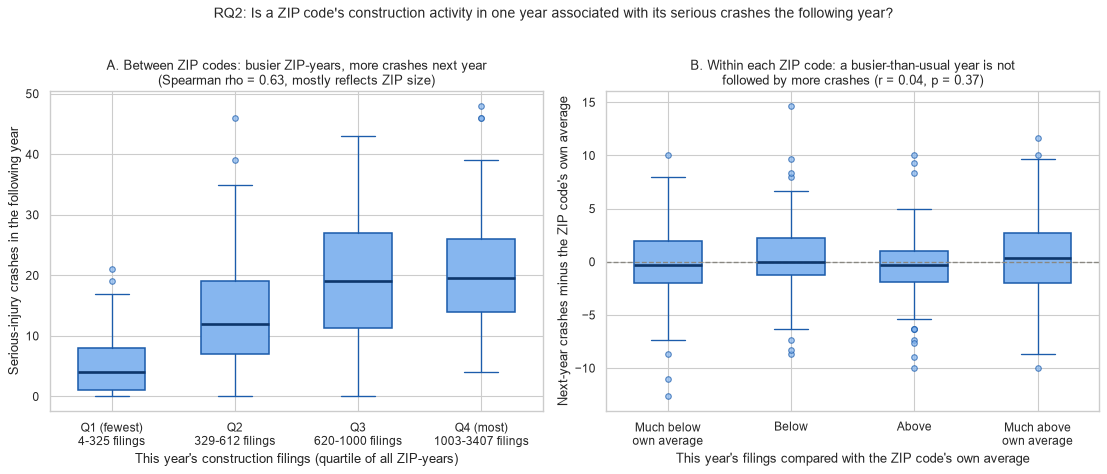

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
box_style = dict(patch_artist=True, widths=0.55, showfliers=True,
                 boxprops=dict(facecolor="#86b6ef", edgecolor="#1c5cab", linewidth=1.4),
                 medianprops=dict(color="#0d366b", linewidth=2.4),
                 whiskerprops=dict(color="#1c5cab", linewidth=1.2), capprops=dict(color="#1c5cab", linewidth=1.2),
                 flierprops=dict(marker="o", markersize=5, markerfacecolor="#86b6ef", markeredgecolor="#1c5cab", alpha=0.7))

# Panel A: between ZIP codes
cats_a = rq2["filing_quartile"].cat.categories
axes[0].boxplot([rq2.loc[rq2["filing_quartile"] == c, "crashes_next_year"] for c in cats_a], **box_style)
axes[0].set_xticks(range(1, 5), [f"{c}\n{summary_between.loc[c, 'filings_range']} filings" for c in cats_a])
axes[0].set_title(f"A. Between ZIP codes: busier ZIP-years, more crashes next year\n"
                  f"(Spearman rho = {rho_b:.2f}, mostly reflects ZIP size)", fontsize=11.5)
axes[0].set_xlabel("This year's construction filings (quartile of all ZIP-years)")
axes[0].set_ylabel("Serious-injury crashes in the following year")

# Panel B: within each ZIP code
cats_b = rq2["dev_quartile"].cat.categories
axes[1].boxplot([rq2.loc[rq2["dev_quartile"] == c, "crash_next_dev"] for c in cats_b], **box_style)
axes[1].axhline(0, color="#898781", linewidth=1.2, linestyle="--")
axes[1].set_xticks(range(1, 5), cats_b)
axes[1].set_title(f"B. Within each ZIP code: a busier-than-usual year is not\n"
                  f"followed by more crashes (r = {r_w:.2f}, p = {p_w:.2f})", fontsize=11.5)
axes[1].set_xlabel("This year's filings compared with the ZIP code's own average")
axes[1].set_ylabel("Next-year crashes minus the ZIP code's own average")

fig.suptitle("RQ2: Is a ZIP code's construction activity in one year associated with its serious crashes the following year?",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

**Findings (RQ2)**
- **Between ZIP codes there is a clear association (Panel A).** ZIP-years in the busiest quarter for construction filings had a median of about 20 serious crashes the next year, against about 4 in the quietest quarter (Spearman rho about 0.63). But this is the same "big, busy ZIP code" pattern as same-year counts (r about 0.41 in both cases). Dense, central ZIP codes have more construction *and* more traffic, so this comparison cannot separate construction from ZIP size.
- **Within each ZIP code there is no association (Panel B).** When a ZIP code had more filings than its own average, its serious crashes the next year were *not* higher than its own average. The four boxes are centred on zero (medians within +/-0.3 crashes) and the correlation is about 0.04 (p = 0.37).
- **The regression agrees.** Once a ZIP code's current crash level is known, 100 extra filings go with only about +0.14 serious crashes the following year, which is practically nothing next to a typical 13 per ZIP-year. Next year's crashes are predicted by this year's crashes, not by construction.

**Interpretation.** Together, RQ1 and RQ2 tell one story. Construction activity and serious crashes are linked **across places** (busy ZIP codes have more of both) but **not over time within a place**, neither in the same year nor one year later. The data offer no sign that more construction in a ZIP code is followed by more serious crashes there. Any differences between ZIP codes are better explained by size, density and traffic, which this dataset does not measure.

**Limitations.** This is correlation only, with no causal claim either way. Each ZIP code has only three filing → next-year pairs, so its own average is noisy and small effects could go undetected. Filings are paperwork: work on site may start months to years after filing, so a one-year lag may be the wrong delay. SIRTA counts only serious-injury crashes. There is no population or traffic data, so we cannot compute risk per person or per vehicle. ZIP codes are coarse, and housing ZIP codes were assigned from the nearest crash.

## 9. Prompts

An AI assistant (Claude) was used to help write and debug the code in this notebook; every result was run and reviewed by the author (Aya Sweed, Member 3). The same list is kept in `docs/prompts.md`. Each entry gives the prompt and, in brackets, what was checked.

1. Check whether the housing data Member 1 used is the real H5 table, and download the full dataset for 2022-2025. (found the local snapshot was an 18,500-row sample with columns that don't exist in H5; wrote `members/member3_integration/fetch_h5_data.py`, which downloaded 598,706 rows)
2. Re-run Member 1's housing notebook on the real data and fix any errors. (fixed the import path for `assign_zip_from_sirta`, a pandas 3 dtype check, and domain checks 4a/4b, which were dropping 316,671 filings with blank height or units; checked that only 633 rows are now removed and that `housing_clean.csv` has 736 rows = 184 ZIPs x 4 years)
3. What exactly should Member 1 fix after the regeneration? (list: dwelling units double-counted across filings of the same job, an uncaught 111,111,111 typo, markdown cells written about the old sample)
4. Draft a task-based plan for my integration work that I can approve step by step. (tasks: key checks, outer merge, post-integration cleaning, derived columns, validation/export, 2 research questions)
5. Create the integration notebook with its goal, inputs/outputs, and a markdown section explaining why we join on ZIP code x year and which alternatives we rejected. (reviewed the reasoning: record level not allowed, borough x year only 20 rows, spatial join and monthly grain considered; noted the nearest-crash ZIP assignment as a limitation)
6. Load both cleaned files and check the join keys before merging: 5-digit text ZIP codes, integer years 2022-2025, unique (zip_code, year) pairs, uppercase boroughs. (all checks passed: housing 736 rows / 184 ZIPs, transport 703 rows / 185 ZIPs; found 4 columns present in both files to resolve after the merge)
7. Merge the two files with an outer join on zip_code + year, chart how many ZIP-years matched / are housing-only / transport-only, and list the one-sided ZIP codes. (738 rows: 701 matched, 35 housing-only, 2 transport-only; checked that every housing-only ZIP has crashes in other years and that the transport-only ZIP 10282 has no filings because of nearest-crash ZIP assignment)
8. Do the post-integration cleaning: resolve the duplicated columns, fill the missing values created by the join, add source flags, and fix data types. For ZIP 10282 (no housing row), use a flag instead of filling filing_count with 0. (0 borough conflicts; replaced 4 coordinate columns with one centroid per ZIP; crash counts set to 0 on 35 housing-only rows but crash rates left blank; added has_housing_data / has_crash_data; checked the before/after missing-value table)
9. Add derived columns: crashes per 100 filings, year-over-year change in filings and crashes, next-year crashes, and severe injuries per 1,000 units (marked provisional until Member 1's unit fix). (year links matched on year +/- 1, not row order; checked each column is blank only where it should be, e.g. crashes_next_year blank for 2025; verified ZIP 11207 by hand)
10. Validate the integrated table and export integrated_dataset.csv: row count, unique keys, totals matching the source files, data contract, plus a column summary for Members 4 and 5. (738 rows x 34 columns; all filing and crash totals equal the source files; re-read the saved CSV to confirm ZIP codes stay 5-digit text)
11. Research question 1: did ZIP codes whose construction activity grew most between 2022 and 2025 also see a larger change in serious crashes? Make a scatter chart with title, axis labels and trend line. (184 ZIP codes; no relationship, Pearson r = -0.07, p = 0.37; checked regression to the mean and per-borough results; wrote limitations, no causal claims)
12. Research question 2: is a ZIP code's construction activity in one year associated with its serious crashes the following year? Compare between ZIP codes and within each ZIP code, with a two-panel box-plot chart. (552 ZIP-years; between ZIP codes Spearman rho = 0.63, within ZIP codes r = 0.04, p = 0.37; regression: 100 extra filings go with +0.14 crashes next year; interpreted as a ZIP-size effect, not a construction effect)
13. Review my prompt log, add a prompts section to the notebook, and draft my 2-3 line contribution entry for the README. (checked the wording and added my name)